# Case - Forecasting Calls with Time Series - Skeleton

### Import packages

In [1]:
import pandas as pd #for dataframes
import matplotlib.pyplot as plt #for plotting
import statsmodels as statsmodels #for models
import numpy as np #for numeric operations
from numpy import fft #for fourier
import seaborn as sns
from tbats import TBATS
import time
import datetime as dt #for working with datetime datatypes
import pylab as pl #for plotting
import scipy.fftpack 
import scipy.stats 
from dateutil.relativedelta import relativedelta

# Import the Holt-Winters package
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.holtwinters import Holt

# Import the ADF package
from statsmodels.tsa.stattools import adfuller

# Import the seasonal decompose package
from statsmodels.tsa.seasonal import seasonal_decompose

# Import the ACF/PACF package and the SARIMAX package
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Import the Box-Ljung test
from statsmodels.stats.diagnostic import acorr_ljungbox

# Import the auto_ARIMA package
from pmdarima.arima import auto_arima

# Import the nsdiffs package
from pmdarima.arima.utils import nsdiffs

# Import the linear regression package
from sklearn import datasets, linear_model
import statsmodels.api as sm

# Import statistics
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# Set random seed
np.random.seed(2345)

In [2]:
import warnings
warnings.filterwarnings('ignore')

### Import and inspect data

In [3]:
data = pd.read_csv("Timeseries_A.csv")
data = data.drop(columns = ['Unnamed: 0'])
# Renaming of columns and adding weekday dummies has already been done.

# b) Overview of the data
data.head()

data.columns.values

array(['year', 'month', 'week', 'day', 'Target A', 'event',
       'summer_break', 'winter_break', 'Target_LY', 'capacity',
       'avg_temp', 'avg_rain', 'Monday', 'Tuesday', 'Wednesday',
       'Thursday', 'Friday', 'Saturday', 'Sunday'], dtype=object)

In [7]:
# c) General data info
print(data.describe())

              year        month         week          day     Target A  \
count  2191.000000  2191.000000  2191.000000  2191.000000  2191.000000   
mean   2012.499772     6.523962    26.584665    15.726609   673.003191   
std       1.707859     3.449207    15.062216     8.800821    99.148316   
min    2010.000000     1.000000     1.000000     1.000000   108.764115   
25%    2011.000000     4.000000    14.000000     8.000000   597.987755   
50%    2012.000000     7.000000    27.000000    16.000000   675.700615   
75%    2014.000000    10.000000    40.000000    23.000000   756.797371   
max    2015.000000    12.000000    53.000000    31.000000   973.605681   

         Target_LY     capacity     avg_temp     avg_rain       Monday  \
count  1826.000000  2191.000000  2191.000000  2191.000000  2191.000000   
mean    672.482735  1175.858103   104.887723    23.454587     0.142857   
std      99.554192   109.646871    62.185098    50.763195     0.350007   
min     108.764115   554.571861  -121

In [9]:
# Add datetimes
data['date'] = pd.to_datetime(data.year*10000+data.month*100+data.day,format='%Y%m%d')
data

,year,month,week,day,Target A,event,summer_break,winter_break,Target_LY,capacity,avg_temp,avg_rain,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,date
0,2010,1,1,4,571.608123,False,False,True,NaN,1078.982909,-29,-1,1,0,0,0,0,0,0,2010-01-04
1,2010,1,1,5,573.336873,False,False,True,NaN,1071.680593,-7,9,0,1,0,0,0,0,0,2010-01-05
2,2010,1,1,6,566.159127,False,False,True,NaN,1003.420811,-30,1,0,0,1,0,0,0,0,2010-01-06
3,2010,1,1,7,554.054642,False,False,True,NaN,1013.611398,-49,-1,0,0,0,1,0,0,0,2010-01-07
4,2010,1,1,8,526.044095,False,False,True,NaN,1008.829390,-50,0,0,0,0,0,1,0,0,2010-01-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2186,2015,12,52,27,553.303071,False,False,True,531.534101,1058.620935,118,-1,0,0,0,0,0,0,1,2015-12-27
2187,2015,12,53,28,584.230241,False,False,True,557.771977,1157.254320,89,0,1,0,0,0,0,0,0,2015-12-28
2188,2015,12,53,29,583.879655,False,False,True,582.090205,985.202268,75,0,0,1,0,0,0,0,0,2015-12-29
2189,2015,12,53,30,576.263058,False,False,True,580.903174,1082.874213,69,0,0,0,1,0,0,0,0,2015-12-30


In [10]:
# Drop rows with NA values
data = data.dropna(axis = 0, how = 'any')
print(data.dtypes)

year                     int64
month                    int64
week                     int64
day                      int64
Target A               float64
event                     bool
summer_break              bool
winter_break              bool
Target_LY              float64
capacity               float64
avg_temp                 int64
avg_rain                 int64
Monday                   int64
Tuesday                  int64
Wednesday                int64
Thursday                 int64
Friday                   int64
Saturday                 int64
Sunday                   int64
date            datetime64[ns]
dtype: object


### Preparation

In [14]:
# b) Aggregate the data to day level
CallsDayLevel = data.groupby(['date'], as_index = False, axis = 0).agg({'Target A':'sum', 'Monday':'first',
                                                                       'Tuesday':'first', 'Wednesday':'first',
                                                                       'Thursday':'first','Friday':'first',
                                                                       'Saturday':'first', 'Sunday':'first', 'event':'first',
                                                                       'avg_temp':'first', 'avg_rain':'first', 'summer_break':'first',
                                                                       'winter_break':'first', 'Target_LY':'sum'}) 

In [ ]:
CallsDayLevel = CallsDayLevel.rename(columns = {'Target A':'calls', 'avg_temp':'temp', 'avg_rain':'rain', 'Target_LY':'calls_l_y'})

In [16]:
"""CallsDayLevel = data.groupby(['date'], as_index = False, axis = 0).agg({'Target A': {'calls': 'sum'}, 
                                                                        'Monday': {'Monday': 'first'},
                                                                        'Tuesday': {'Tuesday':'first'},
                                                                        'Wednesday': {'Wednesday':'first'},
                                                                        'Thursday': {'Thursday':'first'},
                                                                        'Friday': {'Friday':'first'},
                                                                        'Saturday': {'Saturday':'first'},
                                                                        'event': {'event': 'first'},
                                                                        'avg_temp': {'temp': 'first'},
                                                                        'avg_rain': {'rain': 'first'},
                                                                        'summer_break': {'summer_break': 'first'},
                                                                        'winter_break': {'winter_break': 'first'},
                                                                        'Target_LY': {'calls_l_y': 'sum'}})
"""
CallsDayLevel = CallsDayLevel.set_index(['date'])
#CallsDayLevel.columns = CallsDayLevel.columns.droplevel(0)
CallsDayLevel.head()

,calls,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,event,temp,rain,summer_break,winter_break,calls_l_y
date,,,,,,,,,,,,,,
2011-01-01,108.764115,0,0,0,0,0,1,0,False,35,6,False,True,109.534498
2011-01-02,494.596106,0,0,0,0,0,0,1,False,23,-1,False,True,472.225020
2011-01-03,572.642832,1,0,0,0,0,0,0,False,7,1,False,True,516.934298
2011-01-04,578.317813,0,1,0,0,0,0,0,False,9,-1,False,True,571.608123
2011-01-05,571.374682,0,0,1,0,0,0,0,False,3,5,False,True,573.336873


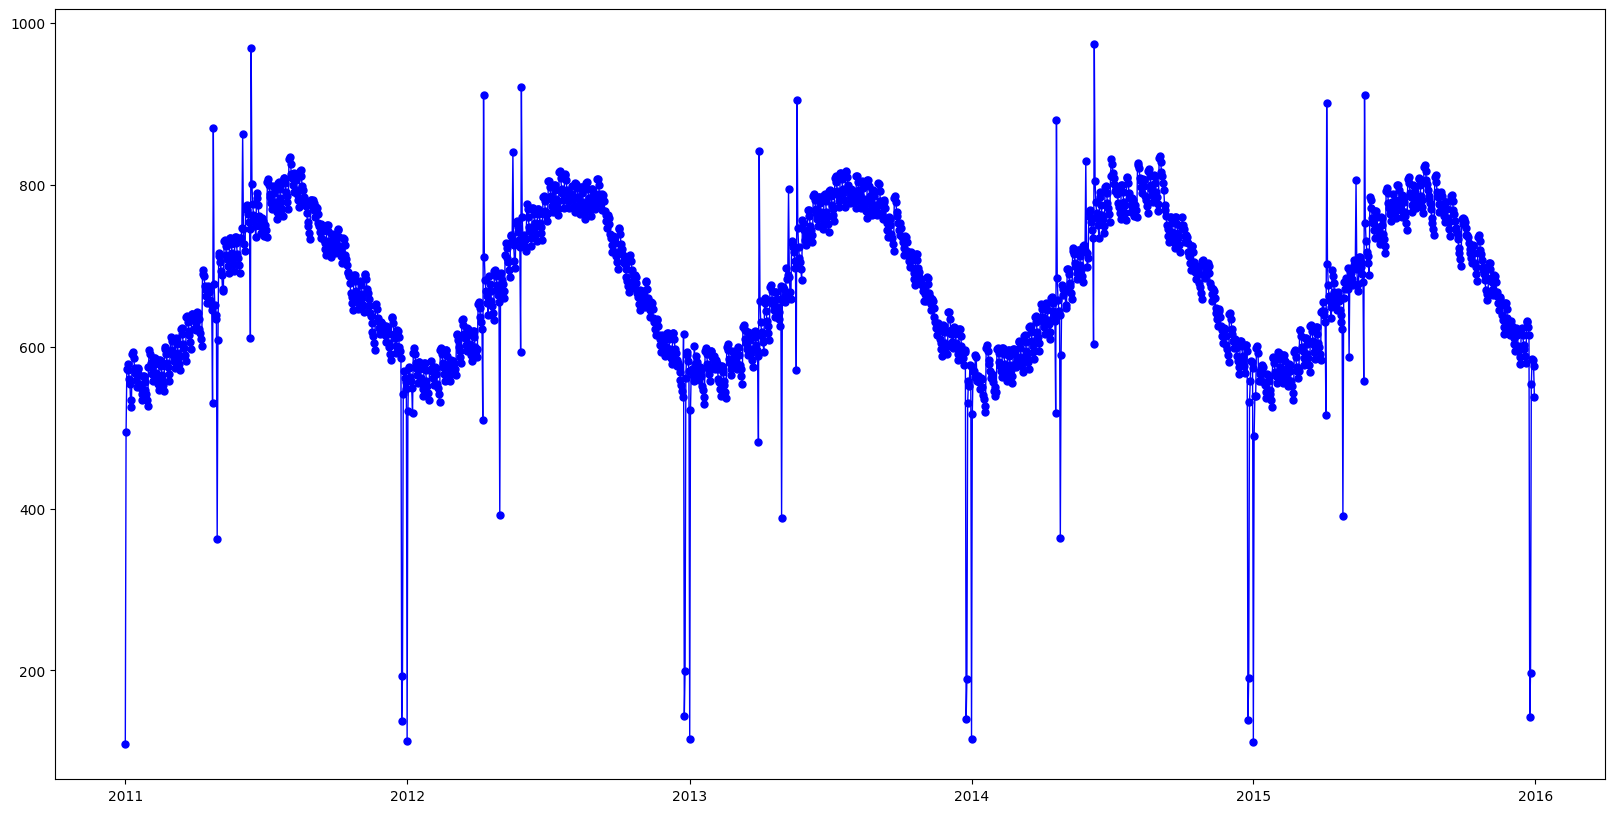

In [21]:
# c) Plot the time series
first_obs = 0
last_obs = len(CallsDayLevel)
plt.figure(figsize=(20, 10))
plt.plot(CallsDayLevel.index[first_obs:last_obs].values,
    CallsDayLevel['calls'][first_obs:last_obs].values, 
     scalex = 20, scaley = 10, color='blue', marker='o', linestyle='solid',
     linewidth=1, markersize=5)

plt.show()

## Decomposition of time series
In this section we will have a look at the various tests you can do before you start modeling a time series

Plot the time series and decompose the signal into trend, seasonality and residuals (noise) using seasonal_decompose()

For the seasonality you have to define the frequency. Here you can choose between a weekly (7) or a yearly (364) pattern. The 364 represents the same weekday a year earlier (so Monday to Monday) as this is more correlated than 365.

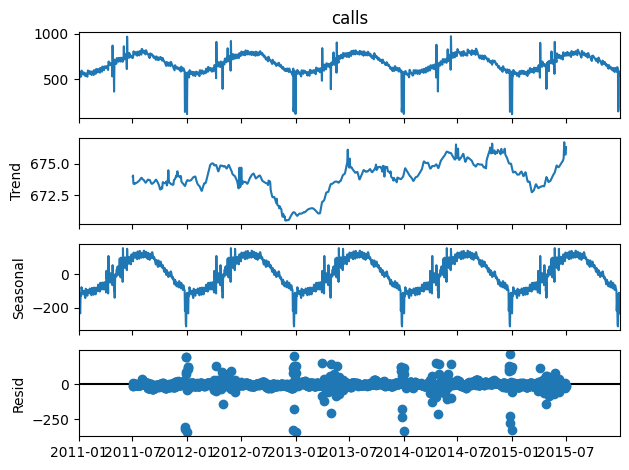

In [22]:
# Step 1 Decompose the data into trend, seasonality and residuals
# Decompose using the seasonal_decompose package

# See how this graph changes when you use different frequencies. The decomposition will try to explain different 
# parts of the signal by seasonal patterns.

result = seasonal_decompose(CallsDayLevel["calls"], model='additive', period=364)

# Plot the results using .plot()
result.plot()
plt.show()

### What do you observe when you look at the decomposed time series?

# Divide data into in and out sample

Number of observations in sample:  1463
Number of observations out of sample:  338
['calls' 'Monday' 'Tuesday' 'Wednesday' 'Thursday' 'Friday' 'Saturday'
 'Sunday' 'event' 'temp' 'rain' 'summer_break' 'winter_break' 'calls_l_y'
 'week']


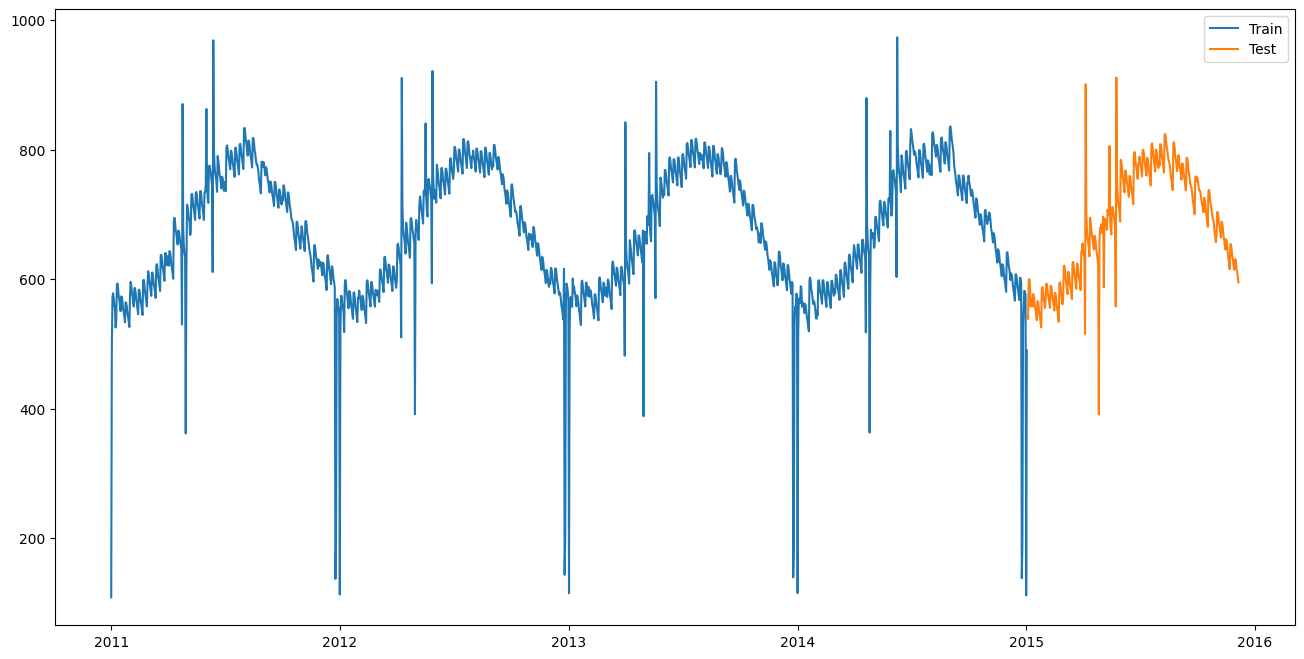

In [28]:
# a) Remove the last section of the sample (shows major disruption of data)
calls = CallsDayLevel['calls'][:-25]

# b) Divide data into a train- and testset

insample_percentage = 0.8
split_at = int(round(CallsDayLevel.shape[0]*insample_percentage/7)*7)
ins = CallsDayLevel.iloc[0:split_at]              # In-sample observations
oos = CallsDayLevel.iloc[split_at:len(calls)]     # Out-of-sample observations

print('Number of observations in sample: ', len(ins['calls']))
print('Number of observations out of sample: ', len(oos['calls']))
print(ins.columns.values)

# b) Visualize the train- and testset
plt.figure(figsize=(16,8))
plt.plot(ins.index, ins['calls'], label='Train')
plt.plot(oos.index, oos['calls'], label='Test')
plt.legend(loc='best')
plt.show()

### Exponential smoothing using Holt-Winters

Estimate the calls on the in sample timeseries using Holt-Winters 

In [34]:
# Change datatypes to prevent overflow
ins['calls'] = ins['calls'].astype(np.float64)
oos['calls'] = oos['calls'].astype(np.float64)

print(ins.dtypes)

# a) Fit HW with 

# CODE BELOW

# Level only
HW1 = ExponentialSmoothing(ins["calls"], trend=None, damped=False, seasonal=None, seasonal_periods=None)
HW1fit = HW1.fit()

# Level and trend
HW2 = ExponentialSmoothing(ins["calls"], trend="add", damped=False, seasonal=None, seasonal_periods=None)
HW2fit = HW2.fit()

# Level and trend
n_periods = 7   # 7: On week level, 365: year level, 91: seasonal level
HW3 = ExponentialSmoothing(ins["calls"], trend="add", damped=False, seasonal="add", seasonal_periods=365)
HW3fit = HW3.fit()


calls           float64
Monday            int64
Tuesday           int64
Wednesday         int64
Thursday          int64
Friday            int64
Saturday          int64
Sunday            int64
event              bool
temp              int64
rain              int64
summer_break       bool
winter_break       bool
calls_l_y       float64
week             UInt32
dtype: object


In [35]:
# b) Create forecast of the different HW-models
fcast_HW1 = HW1fit.forecast(len(oos['calls']))
fcast_HW2 = HW2fit.forecast(len(oos['calls']))
fcast_HW3 = HW3fit.forecast(len(oos['calls']))

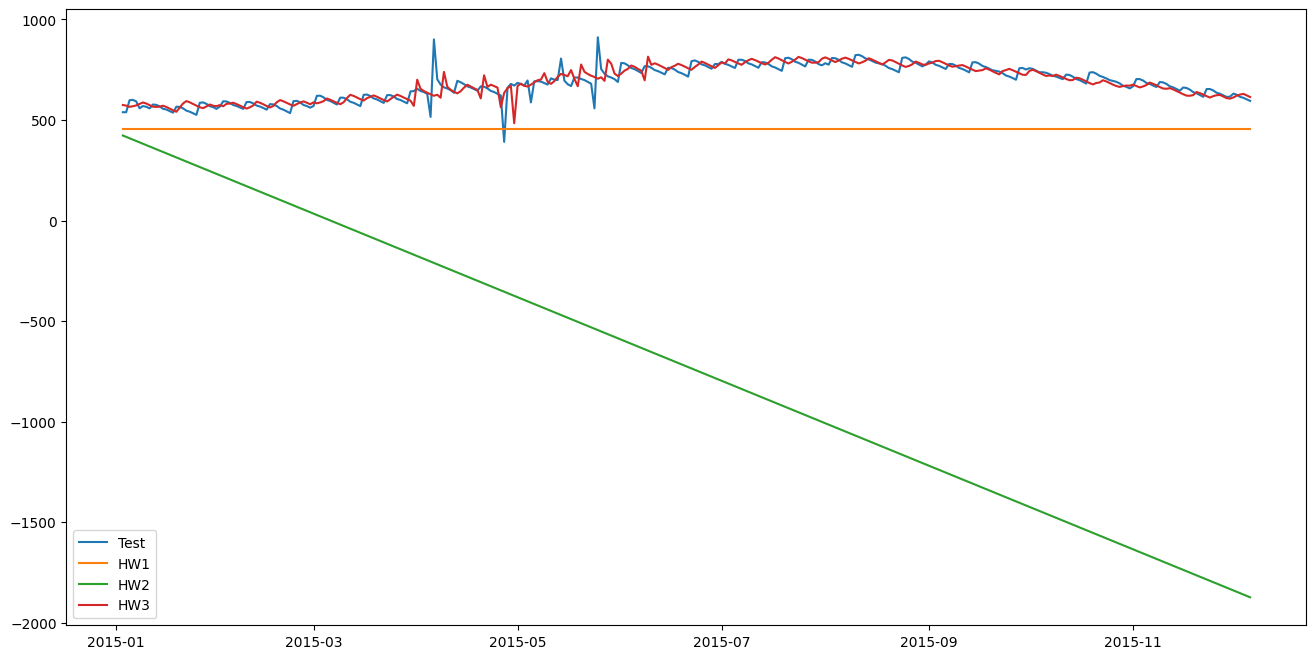

In [37]:
# c) Plot the results of the 3 Holt-Winter forecasts versus the Out Of Sample dataset
plt.figure(figsize=(16,8))
plt.plot(oos.index, oos['calls'], label='Test')
plt.plot(oos.index, fcast_HW1, label='HW1')
plt.plot(oos.index, fcast_HW2, label='HW2')
plt.plot(oos.index, fcast_HW3, label='HW3')
plt.legend()
# CODE HERE 
# PLOT ALL HW1-3

plt.show()



In [48]:
fcast_HW1

2015-01-03    455.34872
2015-01-04    455.34872
2015-01-05    455.34872
2015-01-06    455.34872
2015-01-07    455.34872
                ...    
2015-12-02    455.34872
2015-12-03    455.34872
2015-12-04    455.34872
2015-12-05    455.34872
2015-12-06    455.34872
Freq: D, Length: 338, dtype: float64

In [52]:
# Analyze the out-of-sample accuracy using the MAPE per forecast. Either calculate it yourself or use a package.

MAPE_HW1 = mean_absolute_percentage_error(oos["calls"], fcast_HW1.values)
MAPE_HW2 = mean_absolute_percentage_error(oos["calls"], fcast_HW2.values )
MAPE_HW3 = mean_absolute_percentage_error(oos["calls"], fcast_HW3.values)

print(MAPE_HW1, MAPE_HW2, MAPE_HW3)

0.32621455086298684 1.9997961354122704 0.03856020687271499


#### Stationarity: For ARIMA modeling it is vital that the time series is stationary. This means that its statistical properties (mean, variance, autocorrelation etc.) are constant.

You can check for Stationarity using the Dickey-Fuller test, which returns the ADF statistic and the corresponding p-value. If the ADF statistic is large enough (and p small enough) the time series is considered stationary.

When the time series is not stationary, we will have to perform difference in the ARIMA framework, which is done by increasing the order of I. 

### (S)ARIMA(X)

In [53]:
# Test for stationarity using ADF.
adf_test = adfuller(ins['calls'])
print('ADF Statistic: %f' % adf_test[0])
print('p-value: %f' % adf_test[1])

ADF Statistic: -1.810617
p-value: 0.375204


The nsdiffs() function determines the optimal order of seasonal difference using the Carona-Hansen

In [55]:
# Determine the optimal order of differencing
D = nsdiffs(ins['calls'], m = 365)

print("Optimal order of seasonal differencing:", D)

Optimal order of seasonal differencing: 0


### Check if the model can still be improved: Box-Ljung Test
Using the Box-Ljung test, we can identify if there are still dynamics left in a time series. This would mean that it might be possible to extract additional information from the time series, so we can still further improve our model. 

The Box-Ljung test checks if the residuals of a model (so the error terms) are white noise. It checks the hypothesis if the residuals are independently distributed. If this hypothesis is rejected, you might be able to further improve your model as there are still autocorrelations in the signal.

In [58]:
# Create a white noise signal 
noise_sig = np.random.normal(size=1000)

# Check the results of the Ljung-Box test for the white noise signal
BoxTest  = acorr_ljungbox(noise_sig, lags=None, boxpierce=False)
# Check the pvalues of the signal. If these values are all not-significant the data is considered white noise
BoxTest['lb_pvalue']

# N.B. the .summary() command of the ARIMA model will give the box-ljung test results as well!
#     -> It returns the Box-Ljung value (Q), but more importantly the prob(Q) which is the associated p-value

1     0.386496
2     0.289423
3     0.372446
4     0.388061
5     0.499218
6     0.392981
7     0.254721
8     0.344187
9     0.384035
10    0.441522
Name: lb_pvalue, dtype: float64

####  I. ARIMA(p,d,q)

Inspect the ACF and PACF of the time series

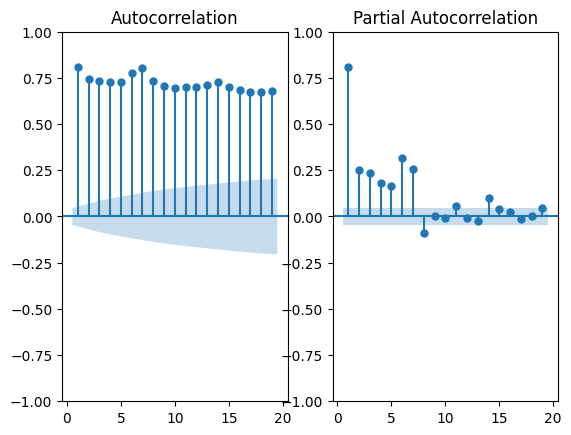

In [59]:
# Check ACF and PACF of time series 
# N.B. if the data set requires differencing, skip this step and first implement a (0,1,0) ARIMA model with differencing
# and inspect the residuals of this model instead.
plt.figure()
plt.subplot(121)
plot_acf(CallsDayLevel['calls'], lags = range(1,20), ax=plt.gca())
plt.subplot(122)
plot_pacf(CallsDayLevel['calls'], lags = range(1,20), ax=plt.gca())
plt.show()

Check the data for seasonal stationarity using the Canova-Hansen test

Step 1: Based on the correlations shown in the ACF plot, determine if you want to add a regular/seasonal AR or MA term. 

Step 2: Check the ACF and PACF of the residuals and determine if an additional order is required using the 

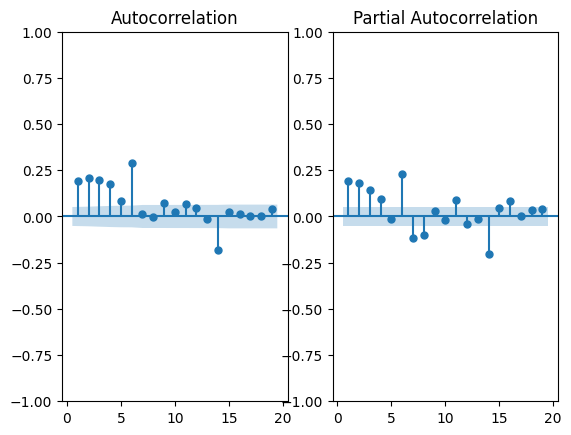

                                     SARIMAX Results                                     
Dep. Variable:                             calls   No. Observations:                 1463
Model:             SARIMAX(1, 0, 0)x(2, 0, 0, 7)   Log Likelihood               -7775.888
Date:                           Wed, 14 Oct 2026   AIC                          15559.776
Time:                                   07:15:19   BIC                          15580.888
Sample:                               01-01-2011   HQIC                         15567.655
                                    - 01-02-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3113      0.010     29.730      0.000       0.291       0.332
ar.S.L7        0.6827      0.010     68.311

In [132]:
# a) Model selection
#    Inspect the pacf and acf plots and iteratively increase the parameters of:
#    1. the ordinary time differences: order=c(x,x,x) 
#    2. the seasonal time differences:  seasonal=list(order=c(x,x,x,period))

# CODE BELOW
period = 7
arima_model = SARIMAX(ins["calls"], order=(1,0,0), seasonal_order = (2,0,0,period), enforce_stationarity = False)
arimafit = arima_model.fit()
# arimafit.plot_diagnostics(figsize=(15, 12))

#    Check ACF and PACF of residuals of model for any available dynamics
# plt.figure()
plt.subplot(121)
plot_acf(arimafit.resid, lags = range(1,20), ax=plt.gca())
plt.subplot(122)
plot_pacf(arimafit.resid, lags = range(1,20), ax=plt.gca())
plt.show()

# #    Evaluate current model performance: Check the Ljung-box coefficient --> Is this signal considered white noise?
print(arimafit.summary())

MAPE_ARIMA: 0.3367137356398077


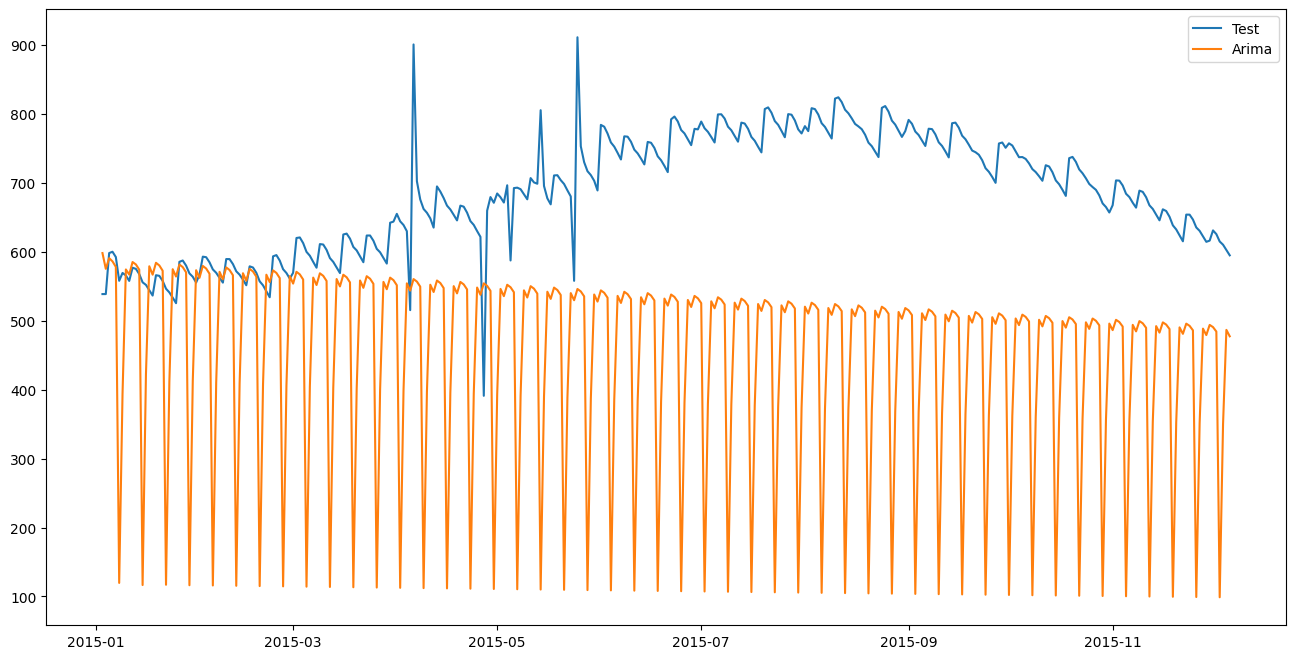

In [135]:
# b) Forecast and analyze the out-of-sample accuracy using the MAPE
fcast_ARIMA = arimafit.forecast(len(oos))

MAPE_ARIMA = mean_absolute_percentage_error(oos["calls"], fcast_ARIMA)
print('MAPE_ARIMA:', MAPE_ARIMA)

# Plot the results of the forecast
plt.figure(figsize=(16,8))
plt.plot(oos.index, oos['calls'].values, label='Test')
plt.plot(fcast_ARIMA, label='Arima')
plt.legend()
plt.show()

#### II. Auto ARIMA(p,d,q)
Auto arima function can determine the AR and MA order as well, but still requires human input for seasonality and differencing.

In [94]:
# a) Model selection
stepwise_model = auto_arima(ins["calls"], 
                            start_p=0, start_q=0, # starting values or AR (p) and MA (q)
                            max_p=2, max_q=2,  # Maximum values for AR (p) and MA (q)
                            m=7, # Seasonality period
                            start_P=0, start_Q = 0, # Starting values for AR (p) and MA(q) of the seasonal term
                            seasonal=True, 
                            d=0, D=0, # Differencing for the ordinary (d) and the seasonal (D) part 
                            trace=True,
                            error_action='ignore',  
                            suppress_warnings=True, 
                            stepwise=True)
print(stepwise_model)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=17642.188, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[7] intercept   : AIC=15743.688, Time=2.17 sec
 ARIMA(0,0,1)(0,0,1)[7] intercept   : AIC=16302.821, Time=0.86 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=23240.969, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[7] intercept   : AIC=16066.285, Time=0.31 sec
 ARIMA(1,0,0)(2,0,0)[7] intercept   : AIC=15715.350, Time=15.39 sec
 ARIMA(1,0,0)(2,0,1)[7] intercept   : AIC=16408.655, Time=14.89 sec
 ARIMA(1,0,0)(1,0,1)[7] intercept   : AIC=15651.143, Time=6.64 sec
 ARIMA(1,0,0)(0,0,1)[7] intercept   : AIC=15868.671, Time=2.95 sec
 ARIMA(1,0,0)(1,0,2)[7] intercept   : AIC=15734.297, Time=11.03 sec
 ARIMA(1,0,0)(0,0,2)[7] intercept   : AIC=15818.092, Time=7.94 sec
 ARIMA(1,0,0)(2,0,2)[7] intercept   : AIC=inf, Time=15.22 sec
 ARIMA(0,0,0)(1,0,1)[7] intercept   : AIC=15903.290, Time=7.10 sec
 ARIMA(2,0,0)(1,0,1)[7] intercept   : AIC=15659.809, Time=5.75 sec
 ARIMA(1,0,1)(1,0,1)[

MAPE_autoARIMA: 0.10565148761179771


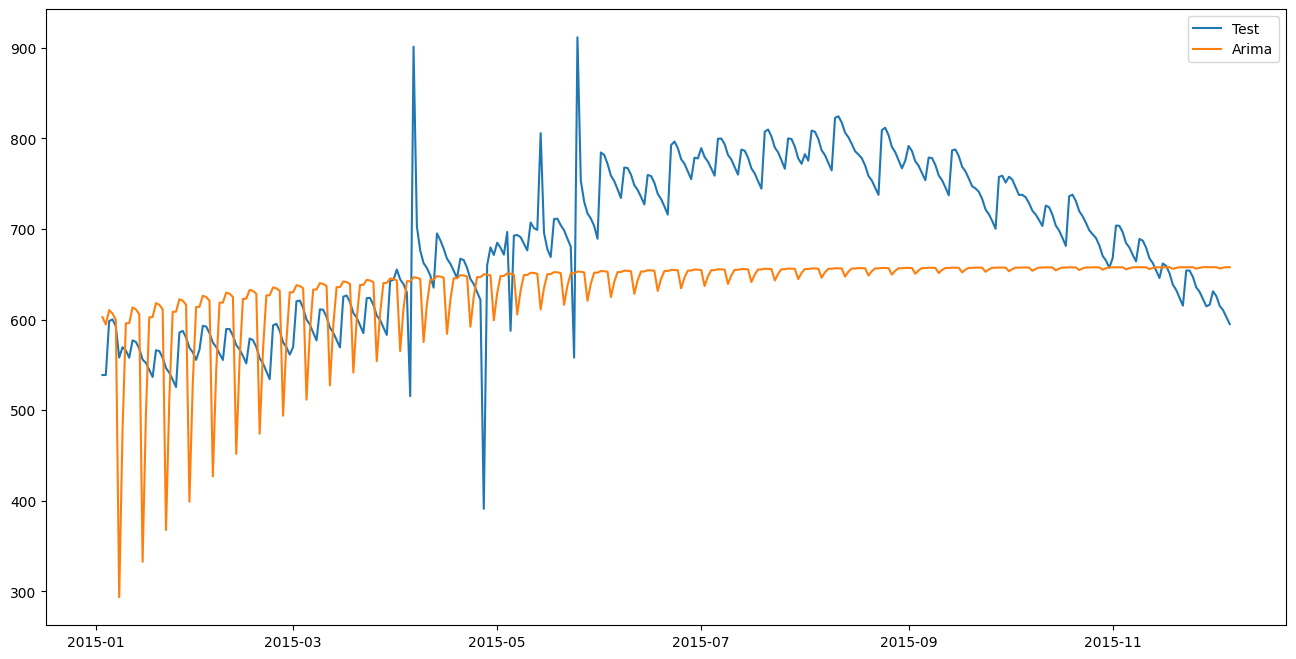

In [136]:
# b) Forecast and analyze the out-of-sample accuracy using the MAPE
fcast_autoARIMA = stepwise_model.predict(len(oos))

MAPE_autoARIMA = mean_absolute_percentage_error(oos["calls"], fcast_autoARIMA)
print('MAPE_autoARIMA:', MAPE_autoARIMA)

# Plot the results of the forecast
plt.figure(figsize=(16,8))
plt.plot(oos.index, oos['calls'].values, label='Test')
plt.plot(fcast_autoARIMA, label='Arima')
plt.legend()
plt.show()

#### II. ARIMAX model

['calls_l_y' 'temp' 'rain' 'Saturday' 'Monday' 'Tuesday' 'Wednesday'
 'Thursday' 'Friday' 'Sunday' 'event' 'winter_break' 'summer_break']


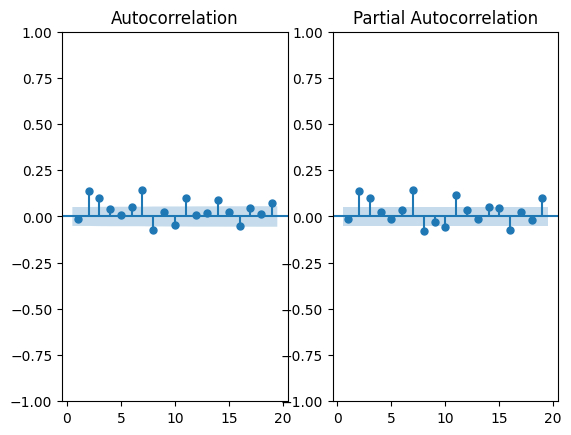

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1463
Model:               SARIMAX(1, 0, 0)   Log Likelihood               -7140.439
Date:                Wed, 14 Oct 2026   AIC                          14310.878
Time:                        06:56:55   BIC                          14390.202
Sample:                             0   HQIC                         14340.466
                               - 1463                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.8230      0.008    105.350      0.000       0.808       0.838
x2             0.1930      0.020      9.689      0.000       0.154       0.232
x3             0.0011      0.020      0.056      0.9

In [109]:
# a) Model selection
#    Inspect the pacf and acf plots and iteratively increase the parameters of:
#    1. the ordinary time differences: order=c(x,x,x) 
#    2. the seasonal time differences:  seasonal=list(order=c(x,x,x,period))

columns = [ # SELECT THE VARIABLES THAT YOU THINK MIGHT BE RELEVANT FOR THE FORECAST
            'calls_l_y'
            ,'temp'
            ,'rain'
            , 'Saturday'
            , 'Monday'
            , 'Tuesday'
            , 'Wednesday'
            , 'Thursday'
            , 'Friday'
            , 'Sunday'
            ,'event'
            ,'winter_break'
            , 'summer_break'
    ]

ins_arimax = ins
ins_arimax[["event", "winter_break", "summer_break"]] = ins_arimax[["event", "winter_break", "summer_break"]].astype(int)
ext_reg_ins = ins_arimax[columns]
print(ext_reg_ins.columns.values)

ext_reg_oos = oos[columns]
ext_reg_oos[[ "event", "winter_break", "summer_break"]] = ext_reg_oos[[ "event", "winter_break", "summer_break"]].astype(int)

# Create ARIMAX model
# CODE BELOW
period = 7
arimax_model = SARIMAX(ins["calls"].values, 
                       order=(1,0,0), 
                       # Seasonality might be useful, but this can also be captured by the weekdays as ext. regressors
                       seasonal_order = (0,0,0,0),
                       exog = ext_reg_ins.values)
arimaxfit = arimax_model.fit()


# Check ACF and PACF of residuals of model for any available dynamics
plt.figure()
plt.subplot(121)
plot_acf(arimaxfit.resid, lags = range(1,20), ax=plt.gca())
plt.subplot(122)
plot_pacf(arimaxfit.resid, lags = range(1,20), ax=plt.gca())
plt.show()

# Evaluate current model performance
print(arimaxfit.summary())

MAPE_ARIMAX: 0.030595382000624585


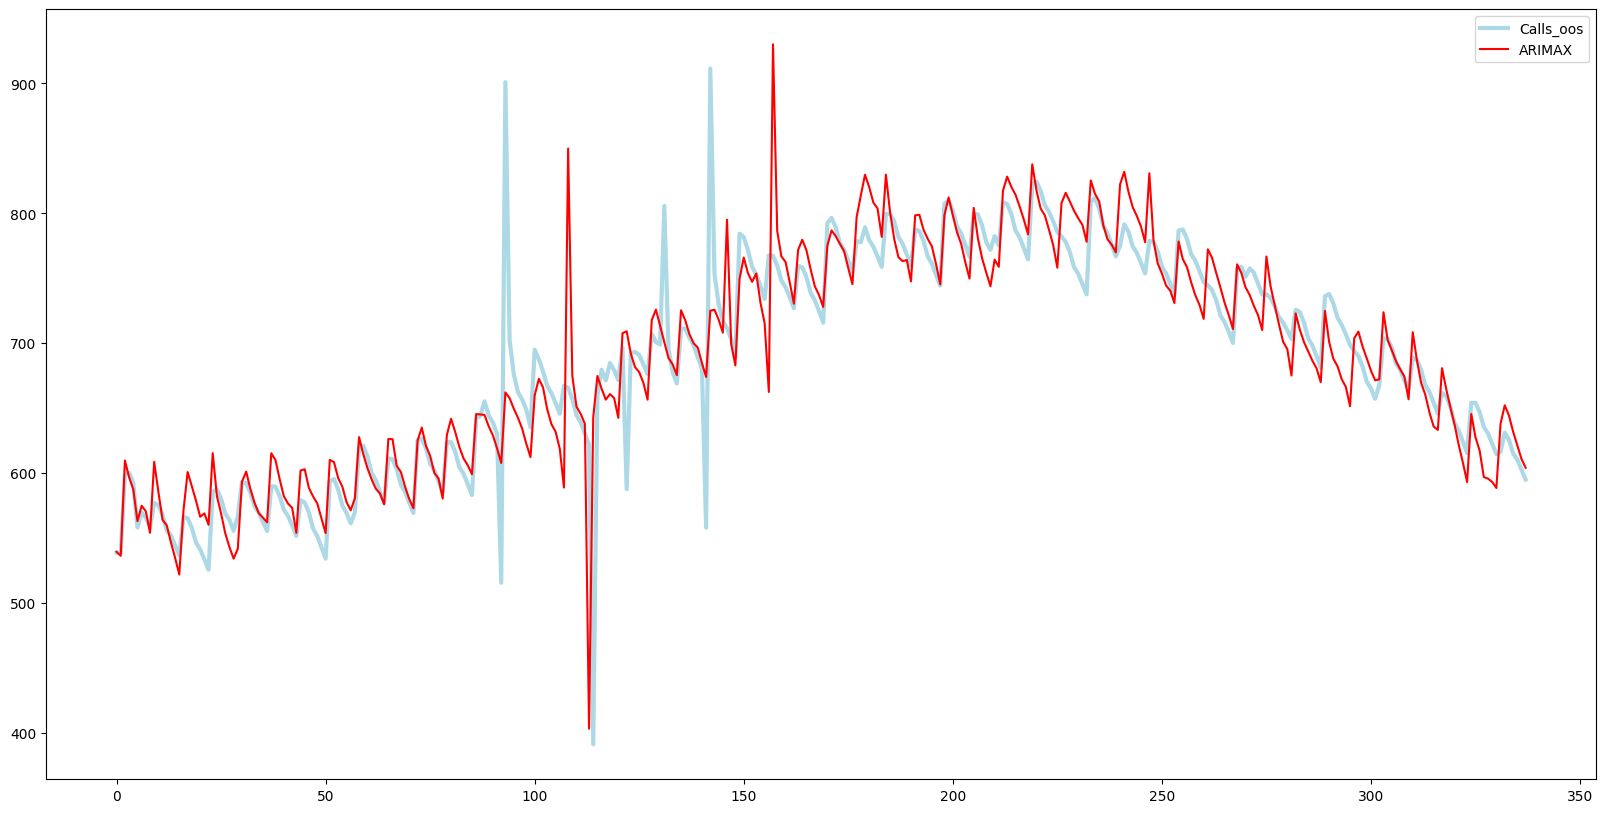

In [112]:
# b) Forecast and analyze the out-of-sample accuracy using the MAPE

# CODE BELOW
start_fc = len(ins)
end_fc = len(ins) + len(oos) - 1

fcast_ARIMAX = arimaxfit.predict(start = start_fc, end = end_fc, exog = ext_reg_oos.values)

MAPE_ARIMAX = mean_absolute_percentage_error(oos["calls"], fcast_ARIMAX)
print('MAPE_ARIMAX:', MAPE_ARIMAX)

# Plot the results of the forecast
plt.figure(figsize=(20,10))
plt.plot(range(0,len(oos)), oos['calls'], 'lightblue', label='Calls_oos', linewidth=3)
plt.plot(fcast_ARIMAX, 'r', label='ARIMAX')  
plt.legend()
plt.show()

### Fourier

First create the power spectral density plot showing the power for different frequencies.

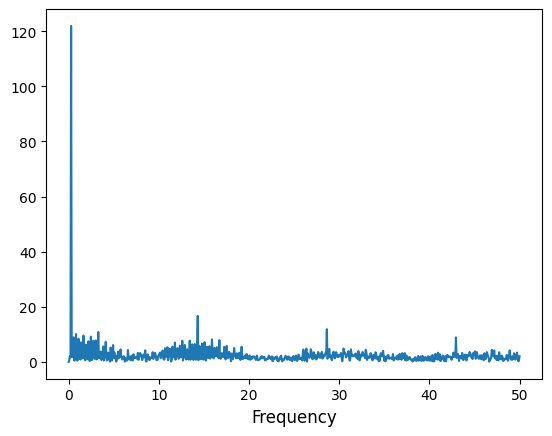

Top 20 frequencies ranked by power:
     index       freq    period  amplitude
0    1459  -0.273411 -3.657500  60.964432
1       4   0.273411  3.657500  60.964432
2    1254 -14.285714 -0.070000   8.342984
3     209  14.285714  0.070000   8.342984
4    1045 -28.571429 -0.035000   5.943301
5     418  28.571429  0.035000   5.943301
6    1415  -3.280930 -0.304792   5.422689
7      48   3.280930  0.304792   5.422689
8      12   0.820232  1.219167   5.069334
9    1451  -0.820232 -1.219167   5.069334
10     24   1.640465  0.609583   4.784398
11   1439  -1.640465 -0.609583   4.784398
12   1427  -2.460697 -0.406389   4.582367
13     36   2.460697  0.406389   4.582367
14   1455  -0.546822 -1.828750   4.465555
15      8   0.546822  1.828750   4.465555
16    836 -42.857143 -0.023333   4.449970
17    627  42.857143  0.023333   4.449970
18   1447  -1.093643 -0.914375   4.202809
19     16   1.093643  0.914375   4.202809


In [114]:
# a) Create periodogram
n = len(ins)     # Number of samplepoints

# Sample spacing used, i.e. with a value > 1, steps will broken up. Increase this value if the spectrum results are
# too coarse. N.B. if you increase h, you have to multiple the results of the spectrum by h to get the true time periods!
h = 100 
t = 1/h 
x = ins.index # dates
y = ins['calls']

# Remove the mean from the dataset to remove the power peak at frequency = 0. Observe difference in FFT with this off
y = y - np.mean(y)        

# Create the periodogram through a fast fourier transform
y_freqdom = fft.fft(y)
xf = np.linspace(0.0, 1.0/(2.0*t), int(n/2))

# Plot the FFT results
fig, ax = plt.subplots()
ax.plot(xf, 2.0/n * np.abs(y_freqdom[:n//2]))
plt.xlabel('Frequency', fontsize=12)
plt.show()

# Sort the frequencies by power to determine the most dominant seasonalitites. 
# Please note: Some of the dominant frequencies might be multitudes or subsections of other frequencies (e.g 7/2 or 14)
f = fft.fftfreq(n)*(1/t)
indexes = list(range(n))
indexes.sort(key=lambda i: np.absolute(y_freqdom[i])/n)
indexes.reverse()

print("Top 20 frequencies ranked by power:\n", pd.DataFrame({'index':indexes,'freq':f[indexes], 'period':1/f[indexes], 'amplitude':np.absolute(y_freqdom[indexes])/n})[0:20])

In [115]:
# b) Define Fourier extrapolation function
def fourierExtrapolation(y, n_predict, n_harm):
    n = len(y)
    t = np.arange(0, n)             # indexing the observations
    p = np.polyfit(t, y, 1)         # find linear trend in y
    y_notrend = y - p[0] * t        # detrended y
    y_freqdom = fft.fft(y_notrend)  # detrended y in frequency domain
    f = fft.fftfreq(n)              # frequencies
    indexes = list(range(n))
    
    # Sort indexes by amplitude, higher -> lower
    indexes.sort(key=lambda i: np.absolute(y_freqdom[i])/n)
    indexes.reverse()
    
    
    # Calculate extrapolation
    t = np.arange(0, n + n_predict)
    restored_sig = np.zeros(t.size)
    for i in indexes[:1 + n_harm * 2]:        
        ampli = np.absolute(y_freqdom[i]) / n  # amplitude
        phase = np.angle(y_freqdom[i])         # phase
        restored_sig += ampli * np.cos(2 * np.pi * f[i] * t + phase)  
    return restored_sig + p[0] * t

27 [0.148 0.058 0.054 0.053 0.053 0.053 0.054 0.053 0.053 0.052 0.052 0.052
 0.052 0.052 0.052 0.052 0.052 0.051 0.051 0.05  0.05  0.049 0.049 0.048
 0.048 0.048 0.048 0.047 0.047 0.047]


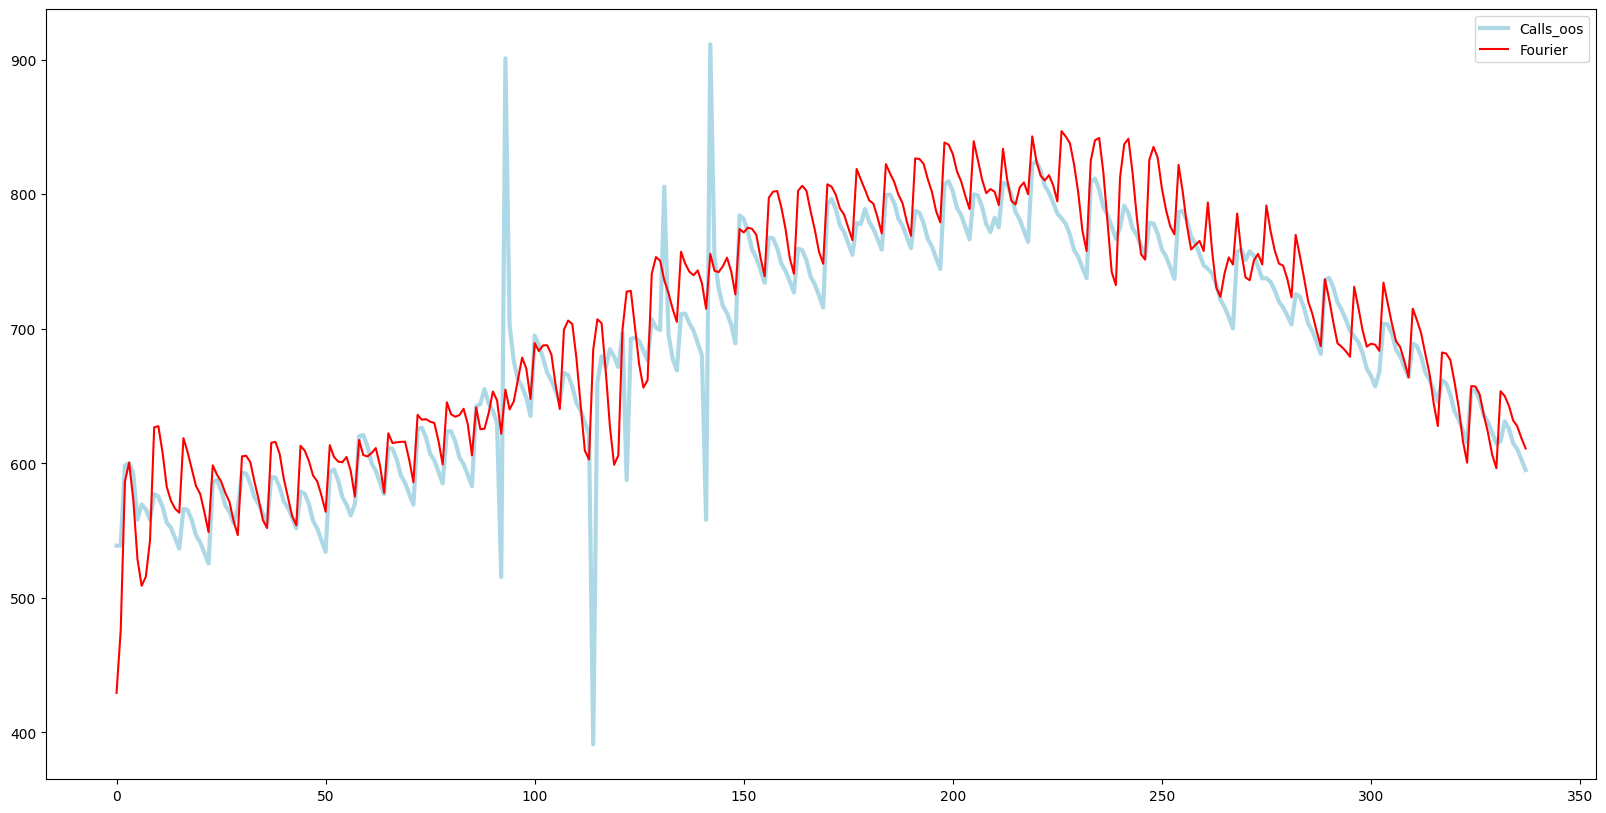

MAPE Fourier: 0.04


In [116]:
# c) Create forecast of the Fourier extrapolation
y = ins['calls']
n_predict = len(oos)

# For-loop with forecasts including 1 to N harmonics to decide on the best set of harmonics. Note: only use in-sample to fit.
MAPE = np.zeros(30)
for n_harm in range(0,30):
    extrapolation = fourierExtrapolation(y, n_predict, n_harm)
    #forecasts = extrapolation[len(y):] 
    in_sample = extrapolation[:len(y)]
    MAPE[n_harm] = round(1.0/len(in_sample) * sum((np.absolute(in_sample - ins['calls']))/ins['calls']), 3) 
    #MAPE[n_harm] = round(1.0/len(forecasts) * sum((np.absolute(forecasts - oos['calls']))/oos['calls']),3)

    
# Select the #harmonics resulting in the best fit
n_harm = MAPE.tolist().index(min(MAPE)) 
extrapolation = fourierExtrapolation(y, n_predict, n_harm)
fcast_Fourier = extrapolation[len(y):] 
print(n_harm, MAPE)
#    Plot forecasting and real values
plt.figure(figsize=(20,10))
plt.plot(range(0,len(oos)), oos['calls'], 'lightblue', label='Calls_oos', linewidth=3)
plt.plot(fcast_Fourier, 'r', label='Fourier')  
plt.legend()
plt.show()

# d) Analyze the out-of-sample accuracy using the MAPE
MAPE_Fourier = round(1.0/len(fcast_Fourier) * sum((np.absolute(fcast_Fourier - oos['calls']))/oos['calls']),3)
print('MAPE Fourier:', MAPE_Fourier)

### TBATS model
Run the TBATS model using the package TBATS. This is done by creating a TBATS object with TBATS() and then running the .fit() function on this object. 

The resulting model can be used to create forecasts with the .forecast() method.

N.B. run time of the TBATS model is significant (~10 minutes) as it is trying out a multitude of different models.

In [117]:
start = time.time()

print('Start')
# required on windows for multi-processing. Does not to work in Jupyter unfortunately (will speed up code).
# see https://docs.python.org/2/library/multiprocessing.html#windows
if __name__ == '__main__':
    
    # CODE BELOW
    
    # Create estimator
    estimator = TBATS(use_box_cox = False, use_trend = False, use_damped_trend = False, seasonal_periods=[7,365])
    print('model set up')

    # Fit model
    TBATS_model = estimator.fit(ins['calls'])
    print('estimation finished')

    # Forecast ahead with length of the OOS
    fcast_TBATS = TBATS_model.forecast(steps=len(oos["calls"]))

    # Summarize fitted model
    print(TBATS_model.summary())


end = time.time()
print("Run time: ", end - start )

Start
model set up
estimation finished
Use Box-Cox: False
Use trend: False
Use damped trend: False
Seasonal periods: [  7. 365.]
Seasonal harmonics [3 6]
ARMA errors (p, q): (5, 2)
Smoothing (Alpha): 0.007336
Seasonal Parameters (Gamma): [-1.88387974e-05 -2.15472972e-05  5.74453711e-06  3.28486593e-06]
AR coefficients [ 5.74453711e-06  3.28486593e-06 -4.23304475e-02 -2.42702614e-02
 -1.02904294e-01]
MA coefficients [0.25402618 0.00839797]
Seed vector [ 658.55545463  -16.38867305   -4.14218562    6.3281935     3.20218201
  -11.16448038   -6.24241484 -109.64815873   -7.50631624   -9.7483366
   -7.9485934    -5.47375694   -9.16817182  -54.6046917     3.27875227
    1.21909269   -2.31202426    3.70386996    1.1761228     0.
    0.            0.            0.            0.            0.
    0.        ]

AIC 21919.088982
Run time:  216.49212908744812


MAPE_TBATS =  0.02550021632571546


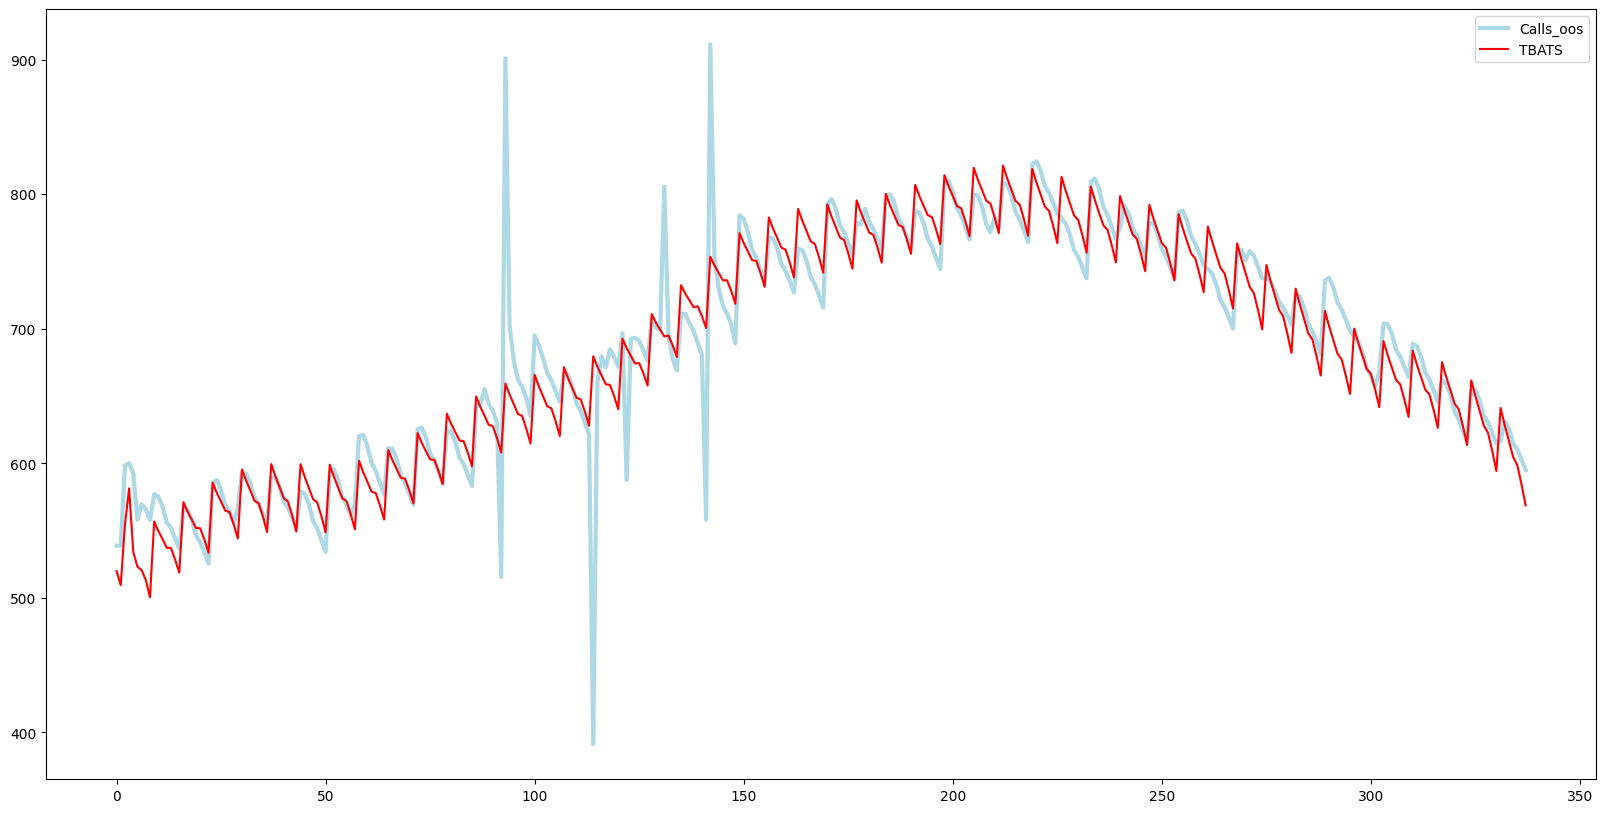

In [118]:
# Find TBATS forecast and MAPE
# CODE BELOW

fcast_TBATS = TBATS_model.forecast(steps=len(oos))

MAPE_TBATS = mean_absolute_percentage_error(oos["calls"], fcast_TBATS)

print("MAPE_TBATS = ", MAPE_TBATS)

# Plot forecasting and real values
plt.figure(figsize=(20,10))
plt.plot(range(0,len(oos)), oos['calls'], 'lightblue', label='Calls_oos', linewidth=3)
plt.plot(fcast_TBATS, 'r', label='TBATS')  
plt.legend()
plt.show()

#### Linear Regression model
As you have seen in the first step of this case, the linear regression model also shows potential when it comes to modeling time series. The main drawback to this procedure is that it requires data manipulation to get all variables in the right format. However, with these steps taken, LinReg can be a powerful forecasting technique.

In [121]:
# b) Estimate the linear model

columns = [ # SELECT THE VARIABLES THAT YOU THINK MIGHT BE RELEVANT FOR THE FORECAST
            'calls_l_y'
            ,'temp'
            ,'rain'
            , 'Saturday'
            , 'Monday'
            , 'Tuesday'
            , 'Wednesday'
            , 'Thursday'
            , 'Friday'
            ,'event'
            , 'winter_break'
            , 'summer_break'
    ]

# CODE BELOW

Y_ins = ins["calls"]
X_ins = ins[columns]
Y_oos = oos["calls"]
X_oos = oos[columns]

# Create linear regression object
X_ins_ols = sm.add_constant(X_ins) # Add a constant to X for the intercept (required in OLS)
X_oos_ols = sm.add_constant(X_oos) # Add a constant to X for the intercept (required in OLS)

regr = sm.OLS(Y_ins, X_ins_ols)
regr = regr.fit()

Evaluate the results of the linear regression. This cannot be created with the LinearRegression model from the sklearn package, which is the main reason we use OLS here.

In [122]:
print(regr.summary())

                            OLS Regression Results                            
Dep. Variable:                  calls   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     1070.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:12:33   Log-Likelihood:                -7145.2
No. Observations:                1463   AIC:                         1.432e+04
Df Residuals:                    1450   BIC:                         1.439e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           83.8533      8.012     10.466   

In [124]:
X_oos

,calls_l_y,temp,rain,Saturday,Monday,Tuesday,Wednesday,Thursday,Friday,event,winter_break,summer_break
date,,,,,,,,,,,,
2015-01-03,569.572327,38,15,1,0,0,0,0,0,False,True,False
2015-01-04,569.981771,39,-1,0,0,0,0,0,0,False,True,False
2015-01-05,563.016609,24,0,0,1,0,0,0,0,False,False,False
2015-01-06,589.162453,28,18,0,0,1,0,0,0,False,False,False
2015-01-07,587.723019,45,12,0,0,0,1,0,0,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
2015-12-02,641.768476,110,0,0,0,0,1,0,0,False,False,False
2015-12-03,633.858390,98,0,0,0,0,0,1,0,False,False,False
2015-12-04,621.686894,94,60,0,0,0,0,0,1,False,False,False


MAPE_reg: 0.03061211407951948


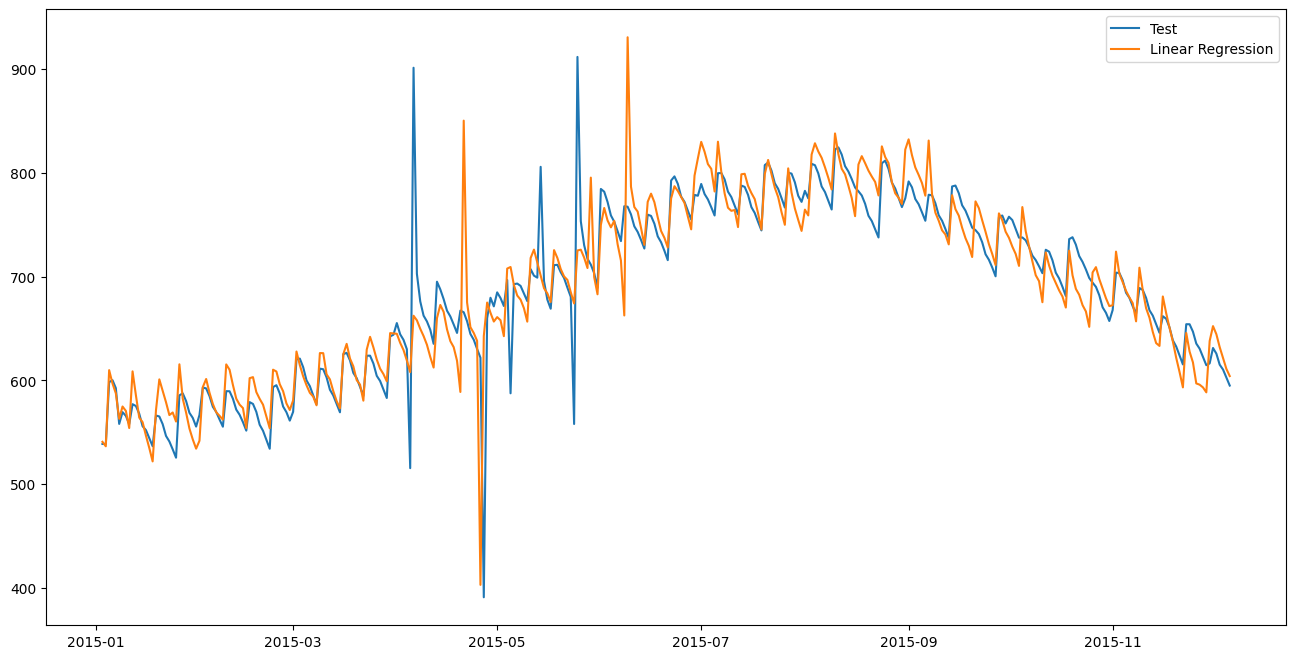

In [126]:
# e) Forecast and analyze the out-of-sample accuracy using the MAPE

# CODE BELOW 

fcast_reg = regr.predict(X_oos_ols)

MAPE_reg = mean_absolute_percentage_error(Y_oos, fcast_reg)
print('MAPE_reg:', MAPE_reg)

#    Plot the results of the forecast
plt.figure(figsize=(16,8))
# plt.plot(ins['Date'], ins['Calls'], label = 'Ins')
plt.plot(oos.index, oos['calls'], label='Test')
plt.plot(oos.index, fcast_reg[:], label='Linear Regression')
plt.legend(loc='best')
plt.show()

### Compare the forecasts created by the different models

In [129]:
print(pd.DataFrame({'model': ['HW3','ARIMA','Auto ARIMA','ARIMAX','Fourier', 'TBATS','LinReg'],
                   'MAPE': [MAPE_HW3,MAPE_ARIMA, MAPE_autoARIMA,MAPE_ARIMAX,MAPE_Fourier, MAPE_TBATS,MAPE_reg]}))

        model      MAPE
0         HW3  0.038560
1       ARIMA  0.105651
2  Auto ARIMA  0.105651
3      ARIMAX  0.030595
4     Fourier  0.040000
5       TBATS  0.025500
6      LinReg  0.030612


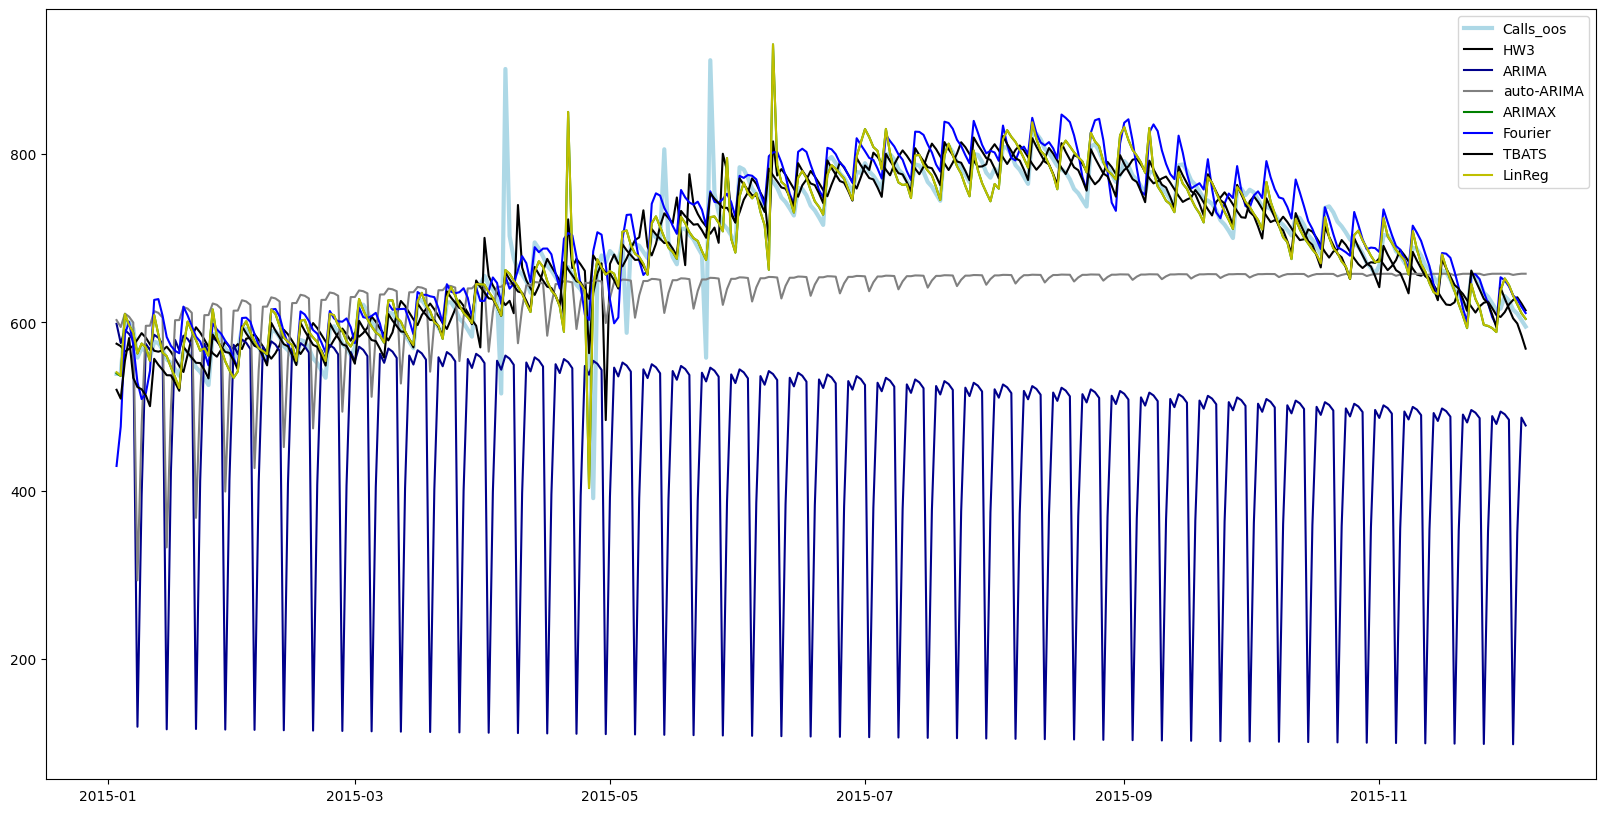

In [139]:
# Plot forecasting and real values
plt.figure(figsize=(20,10))
plt.plot(oos.index, oos['calls'], 'lightblue', label='Calls_oos', linewidth=3)
plt.plot(oos.index, fcast_HW3, 'black', label='HW3')  
plt.plot(oos.index, fcast_ARIMA, 'darkblue', label='ARIMA')  
plt.plot(oos.index, fcast_autoARIMA, 'grey', label='auto-ARIMA')  
plt.plot(oos.index, fcast_ARIMAX, 'g', label='ARIMAX')  
plt.plot(oos.index, fcast_Fourier, 'b', label='Fourier')  
plt.plot(oos.index, fcast_TBATS, 'black', label='TBATS')  
plt.plot(oos.index, fcast_reg, 'y', label='LinReg')  
plt.legend()
plt.show()